# Notebook 06 — A ceiling camera that helps the robot: from "the goal is over there" to "drive here next"

Notebooks 04 and 05 left the robot with two weaknesses:

1. **Goals that start out of view.** The robot only sees what is in front of it and has no memory, so a hidden goal
   has to be found by searching.
2. **Getting stuck on obstacles**, mostly when a box stands between the car and the goal.

Many real rooms have a camera on the ceiling (warehouses, labs, smart homes). It sees **the whole room at once**: the
car, the goal and every obstacle. This notebook asks:

> **Can an off-car "server" read a ceiling camera and send the car a small message that makes it find the goal more
> often and faster, without sending the picture itself (to save bandwidth)?**

**Short answer: yes, but only once the message is a *route*, not a *direction*.** We got there in three experiments:

| Experiment | What the server tells the car | Success (128 test rooms) | What we learned |
|---|---|---|---|
| — | nothing (front camera only) | 75% | the baseline |
| 1. Direction help | where the car and goal are, and which way the goal is | 74–77% | even *perfect* directions don't raise success: they point the car straight into the box in the way |
| 2. Perfect route | the next points on the shortest obstacle-free path (from the simulator's map) | **99%** | the right kind of help: an upper limit |
| 3. Real route | the same, but worked out by the server from the ceiling picture | **91%** | it works for real: 29 rooms won and 9 lost against the front-camera car, far beyond luck |
| 3b. Real route, better map | the same, with the server's obstacle map trained longer | **94%** | better on every measure (the gain over 3 itself is not yet proven) |

The message in experiment 3 is **9 numbers (36 bytes) every half second**.

**What you will learn here**
1. How to bolt extra information onto a vision-language-action model (smolVLA) as extra input tokens.
2. How to test whether a model really *uses* an input: switch it off, and feed it the wrong one.
3. Why vision-language models (VLMs) are bad at exact positions and path planning, and the standard fix: **the VLM
   decides *what* (which object, what is an obstacle), simple geometry works out *where* and *how*.**
4. How to diagnose a failure with data (here: "which rooms does the car fail in?") instead of guessing.
5. How to read luck tests when comparing two models on the same rooms.

**How this notebook runs.** The full pipeline is long (about a day of computing from scratch on an RTX 4080 SUPER +
20-core CPU, mostly the server's practice pictures and training). Every long step is a script; each code cell runs its
script **only if its results don't exist yet**, so with the project's results in `runs/` the whole notebook runs in a
few minutes and just draws the charts. Set `FORCE = True` in a cell to redo that step.

## 1. Setup

Same as the other notebooks: find the project folder, import the helpers, check the GPU. Close other notebooks that
hold a model first: the server (SmolVLM2) plus a car model need about 10 GB of GPU memory during the tests.

In [1]:
import os, sys, json, shutil, subprocess
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # must happen before torch is imported
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
RUNS = PROJECT_ROOT / "runs"

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

from carsim import nb06
from carsim.device import describe
print(describe())
if shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi", "--query-gpu=memory.used,memory.total", "--format=csv"], capture_output=True, text=True).stdout)

device = cuda: NVIDIA GeForce RTX 4080 SUPER, 15.6 GB | PyTorch 2.15.0+cu134 | Linux 7.2.14-arch1-1
memory.used [MiB], memory.total [MiB]
802 MiB, 16376 MiB



## 2. The ceiling camera and the roof marker

**The camera** hangs 9.5 m up above the near wall and looks down at about 60°, like a real ceiling camera in a
corner. A camera pointing straight down would need to hang much higher to see the whole 8 × 8 m room. Every picture moves the
camera by up to ±0.3 m and its aim by ±0.2 m at random ("jitter"): a real camera is never mounted exactly where
planned, and a model trained on one exact view can learn pixel positions by heart instead of reading the room.
(`carsim/overhead.py`)

**The roof marker.** From 9.5 m up the car is a small blue box, and its 2 cm red bumper is invisible, so you can't
tell which way it faces. We put a two-colour arrow on its roof: a **hot-pink** chevron at the front and a **cyan**
shaft at the back. Those two colours appear nowhere else in the room, and two colours make "front" and "back"
impossible to confuse. The marker sits behind the car's camera mast, so **the car's own camera picture is pixel-for-pixel
unchanged** (we checked): everything learned in notebooks 03–05 still applies.

The cell below draws one room from the ceiling and from the car.

[I 11/15/26 23:26:33.498 214020] [shell.py:_shell_pop_print@25] Graphical python shell detected, using wrapped sys.stdout


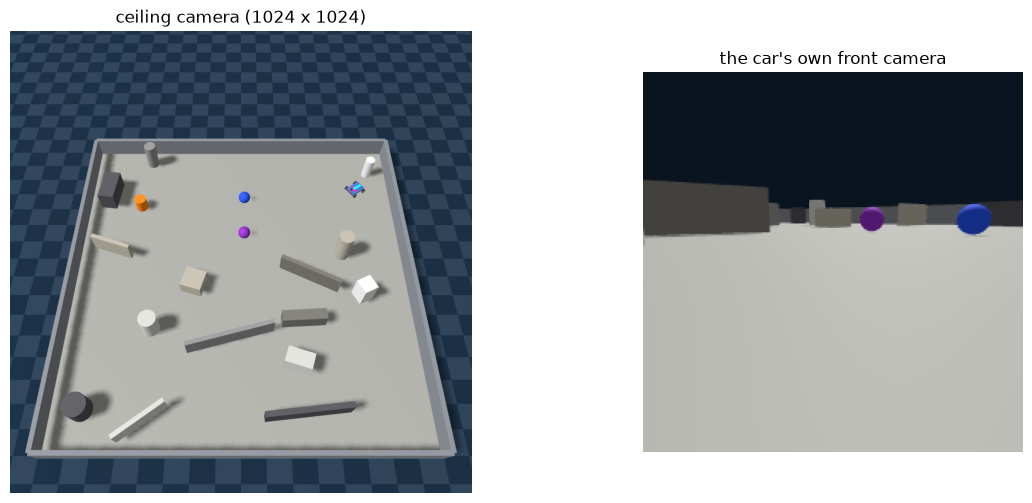

In [2]:
over, front = nb06.overhead_and_front(seed=11)
fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].imshow(over); ax[0].set_title("ceiling camera (1024 x 1024)"); ax[0].axis("off")
ax[1].imshow(front); ax[1].set_title("the car's own front camera"); ax[1].axis("off")
plt.show()

## 3. Better demonstrations: a driver that follows the route

Notebook 02's scripted driver **searched**: turn until the goal is in view, then drive to it. That is the right
teacher for a car that only has its front camera, but the wrong one for a car that gets help: if the help says "the
goal is behind you, around that box", the teacher should drive *straight there*, not search.

So we re-drove **the same 296 layouts** with the map-aware driver (`PathFollowingExpert` in `carsim/expert.py`): it
follows the shortest obstacle-free path from the simulator's map, with a 0.3 m "carrot" point ahead of the car, and
finishes like a human driver (slows down and stops ~12 cm from the goal). Result: **294 drives, 15,494 frames**;
drives that start with the goal hidden take 5.8 s instead of 8.5 s.

The training file uses **the same validation and left-out layouts** as notebook 03, so all results stay comparable.
Six recorders run in parallel on the CPU (about 30 minutes).

In [3]:
FORCE = False
jobs = []
for kind in ("rooms", "words"):
    for i in (1, 2, 3):
        out = RUNS / "datasets" / f"expert_pf_{kind}_{i}"
        if out.exists() and not FORCE:
            continue
        extra = ["--words", "--words-mix", "search"] if kind == "words" else []
        cmd = [sys.executable, "scripts/record.py", "--expert", "--cpu", "--finish", "human", "--dataset", str(out),
               "--episodes", "0", "--seed-list", f"assets/scripted_layouts/{kind}_{i}.jsonl", *extra]
        jobs.append(subprocess.Popen(cmd, cwd=PROJECT_ROOT, stdout=open(f"{out}.log", "w"), stderr=subprocess.STDOUT))
for j in jobs:
    j.wait()
print(f"recorded {len(jobs)} folders" if jobs else "already done: runs/datasets/expert_pf_*")
nb06.run(["scripts/route_follow_prep.py"], ["runs/datasets/route_follow_prep.json"], force=FORCE)

already done: runs/datasets/expert_pf_*
already done: runs/datasets/route_follow_prep.json


## 4. The server: a bigger VLM that reads the ceiling picture

The **server** runs off the car (on a PC or in the cloud). It reads the ceiling picture plus the instruction and
sends the car a small summary. We use the full **SmolVLM2-500M**, the model smolVLA itself was built from:

| | the car's reader (inside smolVLA) | the server (SmolVLM2) |
|---|---|---|
| language layers | the first 16 of 32 | all 32 (the last 4 fine-tuned for this job) |
| how it looks at a picture | one 512 px view → 64 tokens | 1024 px cut into 4 tiles + the whole view → 5 × 64 = 320 tokens |
| reads | the front camera | the ceiling camera + the instruction |

**What it learns.** "Facts" that the simulator gives us for free as labels: the car's position and heading, the named
object's position, and the goal's direction and distance *from the car*. Training pictures: 48,000 pictures of
9,000 random rooms with the car anywhere, facing anywhere (`scripts/overhead_data.py` picks the scenes,
`scripts/overhead_data_native.py` renders and encodes them; half of them are "arrow practice": the same spot at 4
headings). The picture tokens are computed once and cached, so training only runs the language layers.

**How we got here (the short version of a long investigation).** The first server used the car's own 16-layer reader
on a 64-token picture and got the goal's rough direction (ahead / left / behind / right) right only 39–46% of the
time. Measuring each stage showed two problems. Each 64-token picture keeps only coarse positions. And the reader
couldn't link the *words* ("the red cube") to the right object in the picture. The full model with tiles, plus a
summariser steered by the instruction's words, reached 66–71%. Then two fixes for the car's heading, which the model kept reading backwards:
extra arrow-practice pictures and the two-colour marker. They reached **about 75%**.

Two training stages of 6,000 steps, about 45 minutes each.

*Looking ahead:* in the final system (section 8.5) SmolVLM2 keeps only the jobs it turns out to be good at: reading
the instruction to decide **which** object is the goal, and providing the picture features from which a small map
reader learns **what an obstacle looks like**. Exact positions and the path are handed to simple, exact methods.

In [4]:
FORCE = False
nb06.run(["scripts/overhead_data.py"], ["runs/overhead_pretrain/train/meta.npz"], force=FORCE)                      # scenes
nb06.run(["scripts/overhead_data_native.py", "--out", "runs/overhead_native2", "--marker", "two"],
         ["runs/overhead_native2/train/feats.npy"], force=FORCE)
nb06.run(["scripts/overhead_data_native.py", "--out", "runs/overhead_native2", "--marker", "two", "--splits", "val_heading", "train_heading"],
         ["runs/overhead_native2/train_heading/feats.npy"], force=FORCE)
nb06.run(["scripts/train_server_native.py", "--batch", "64", "--data", "runs/overhead_native2", "--out", "runs/checkpoints/server_native2_u4_s0.pt"],
         ["runs/checkpoints/server_native2_u4_s0.pt"], force=FORCE)
nb06.run(["scripts/train_server_native.py", "--batch", "64", "--heading", "--data", "runs/overhead_native2",
          "--init", "runs/checkpoints/server_native2_u4_s0.pt", "--out", "runs/checkpoints/server_native2_u4_heading_s0.pt"],
         ["runs/checkpoints/server_native2_u4_heading_s0.pt"], force=FORCE)
SERVER = RUNS / "checkpoints" / "server_native2_u4_heading_s0.pt"

already done: runs/overhead_pretrain/train/meta.npz
already done: runs/overhead_native2/train/feats.npy
already done: runs/overhead_native2/train_heading/feats.npy
already done: runs/checkpoints/server_native2_u4_s0.pt
already done: runs/checkpoints/server_native2_u4_heading_s0.pt


**The training charts** (stage 1, then stage 2 = heading practice). Left: the training loss. Middle: how often the
goal's rough direction is right on rooms the server never saw ("val_rooms") and on the validation driving rooms
("val_drive"). Right: position errors in metres.

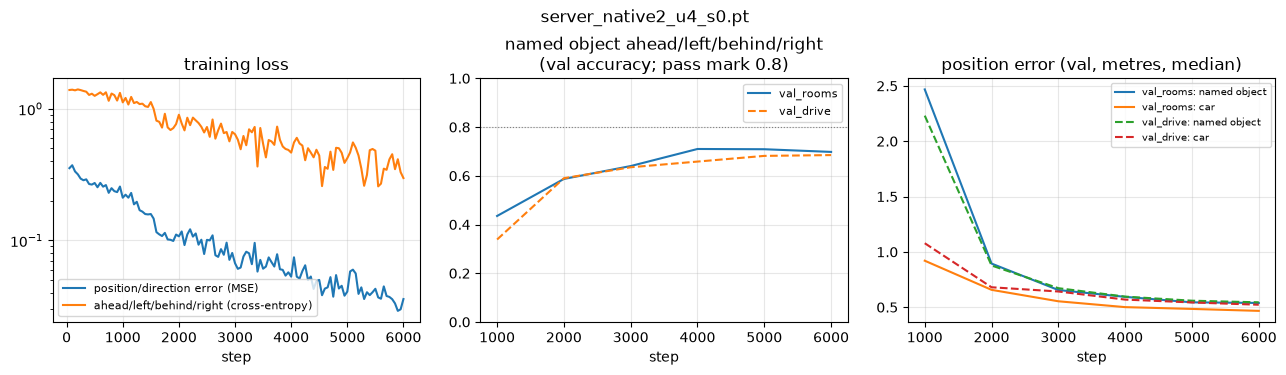

{'car_xy_m': 0.522, 'heading_deg': 15.171, 'obj_xy_m': 0.544, 'rel_dir_deg': 19.451, 'rel_dir_within45': 0.79, 'heading_reversed': 0.048, 'rel_dist_m': 0.383, 'dir4_acc': 0.685, 'dir4_from_angle_acc': 0.665}


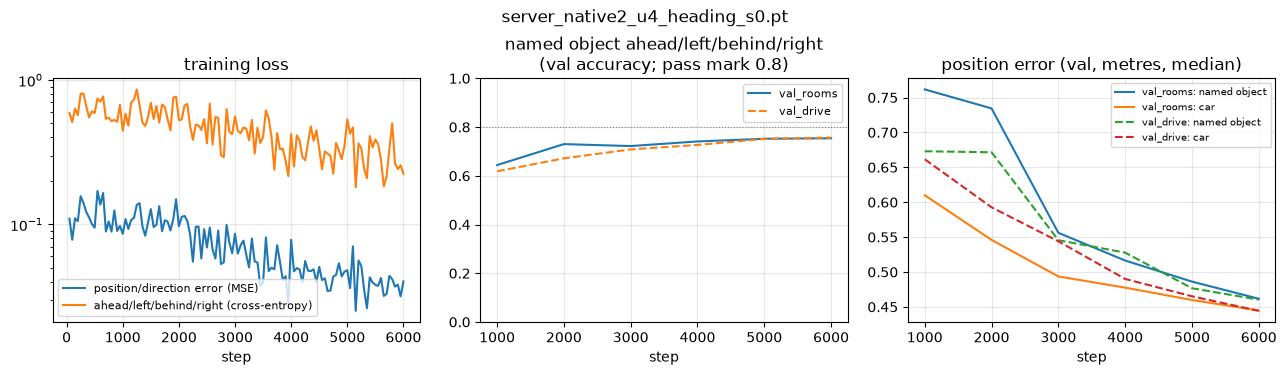

{'car_xy_m': 0.444, 'heading_deg': 10.814, 'obj_xy_m': 0.46, 'rel_dir_deg': 15.584, 'rel_dir_within45': 0.835, 'heading_reversed': 0.038, 'rel_dist_m': 0.377, 'dir4_acc': 0.757, 'dir4_from_angle_acc': 0.737}


In [5]:
from carsim.server import plot_server_training
for p in ["server_native2_u4_s0.pt", "server_native2_u4_heading_s0.pt"]:
    log = torch.load(RUNS / "checkpoints" / p, map_location="cpu", weights_only=False)["log"]
    plot_server_training(log).suptitle(p, y=1.03); plt.show()
    last = log[-1]
    print({k.split("/")[1]: round(v, 3) for k, v in last.items() if k.startswith("val_drive/") and not k.endswith("majority")})

**What you should see** (final server, rooms it never saw): goal direction within 45° about 84–87% of the time,
heading typically 10° off **but backwards about 4% of the time**, car and goal positions typically **0.44–0.46 m** off.
The direction is good enough to be useful. The positions and the backwards readings will matter later (section 8).

The cell below runs the frozen server once on every frame of the driving data, so the cars can be trained with its
outputs (`scripts/overhead_frames.py`, about an hour). It also stores the picture tokens, which section 8 reuses.

In [6]:
nb06.run(["scripts/overhead_frames.py"], ["runs/overhead_frames/route_follow/facts_pred.npy"], force=False)

already done: runs/overhead_frames/route_follow/facts_pred.npy


## 5. Experiment 1: help as directions ("the goal is over there")

**How the help gets into the car.** smolVLA's reader takes a row of tokens: the front-camera picture (64 tokens), the
instruction words and the car's speed. We insert **8 extra "guidance" tokens right after the picture**
(`carsim/guidance.py`). A small new layer turns the help into those 8 tokens. Because the instruction comes after
them, the words can link the named object to both the picture and the help. When there's no help, the car gets a
learned **"no help"** set of tokens, so it always knows whether help is present.

**The cars** (all with notebook 04's recipe on the route-following demos, `scripts/train_guided.py`):

| Car | Gets | Why |
|---|---|---|
| **front camera only** | nothing extra | the baseline every helped car must beat |
| **perfect facts** | the simulator's true facts (9 numbers) | the best case: what if the server were never wrong? |
| **server facts** | the server's predicted facts | the realistic version of the above |
| **server message** | the server's 8 × 128 summary (2 KB) | the original "context vectors" design |
| **whole ceiling picture** | the ceiling picture's 64 tokens, read by the car's own reader | "just add a second camera" |

During training each sample has its help removed half the time, so the car also learns to drive without it (a car
trained with help always present fails badly without it: "A Good Time to Ask", arXiv 2206.10606). The helped cars start
from the trained "perfect facts" car and only get a fresh help layer (a warm start, which avoids learning to ignore
a help that starts out as noise).

already done: runs/checkpoints/car06_Cstar_s0.pt
already done: runs/checkpoints/car06_F_s0.pt
already done: runs/checkpoints/car06_C_s0.pt
already done: runs/checkpoints/car06_A_s0.pt
already done: runs/checkpoints/car06_I_s0.pt


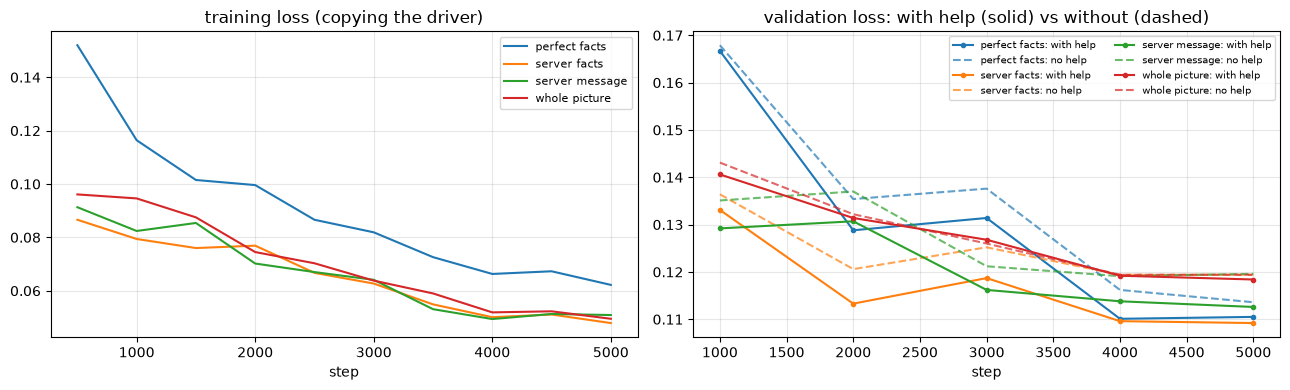

In [7]:
FORCE = False
CK = RUNS / "checkpoints"
nb06.run(["scripts/train_guided.py", "--model", "Cstar"], [CK / "car06_Cstar_s0.pt"], force=FORCE, log=RUNS / "car06_logs" / "Cstar_s0.log")
nb06.run(["scripts/train_guided.py", "--model", "F"], [CK / "car06_F_s0.pt"], force=FORCE, log=RUNS / "car06_logs" / "F_s0.log")
for m in ("C", "A", "I"):
    nb06.run(["scripts/train_guided.py", "--model", m, "--init", CK / "car06_Cstar_s0.pt"], [CK / f"car06_{m}_s0.pt"],
             force=FORCE, log=RUNS / "car06_logs" / f"{m}_s0.log")
nb06.plot_car_training({"perfect facts": RUNS / "car06_logs/Cstar_s0.log", "server facts": RUNS / "car06_logs/C_s0.log",
                        "server message": RUNS / "car06_logs/A_s0.log", "whole picture": RUNS / "car06_logs/I_s0.log"}); plt.show()

**Reading the chart.** If a car uses its help, its validation loss *with* help (solid) must sit clearly below the
loss *without* help (dashed). Here every gap is small (about 0.11 vs 0.12): a first hint that direction help adds
little to copying the route-following driver.

**The tests.** Each car drives the same **128 test rooms** as notebooks 04 and 05, with the server running **live**
on the ceiling picture (`scripts/car06_tests.py`). Helped cars drive three times:
* **with help** (normal);
* **help switched off**: if the car gets worse, it was relying on help;
* **help from a different room** (each car gets its neighbour simulator's help): if the car gets worse, it reads
  *what the help says*, not just *whether* help is there.

In [8]:
FORCE = False
for name in ("F", "Cstar", "C", "A", "I"):
    nb06.run(["scripts/car06_tests.py", "--car", CK / f"car06_{name}_s0.pt", "--server", SERVER, "--out", f"runs/car06_tests/{name}_s0.json"],
             [f"runs/car06_tests/{name}_s0.json"], force=FORCE)
EXP1 = [("front camera only", "F_s0", "help"), ("perfect facts", "Cstar_s0", "help"), ("server facts", "C_s0", "help"),
        ("server message", "A_s0", "help"), ("whole ceiling picture", "I_s0", "help")]
display(nb06.summary(EXP1))
display(nb06.summary([("perfect facts: help on", "Cstar_s0", "help"), ("perfect facts: help OFF", "Cstar_s0", "no_help"),
                      ("perfect facts: WRONG-room help", "Cstar_s0", "other_room"),
                      ("server facts: help on", "C_s0", "help"), ("server facts: help OFF", "C_s0", "no_help"),
                      ("server facts: WRONG-room help", "C_s0", "other_room"),
                      ("server message: help on", "A_s0", "help"), ("server message: help OFF", "A_s0", "no_help"),
                      ("server message: WRONG-room help", "A_s0", "other_room")]))

already done: runs/car06_tests/F_s0.json
already done: runs/car06_tests/Cstar_s0.json
already done: runs/car06_tests/C_s0.json
already done: runs/car06_tests/A_s0.json
already done: runs/car06_tests/I_s0.json


,success,goal hidden at start,box in the way,touched something,s per success,"s per success, hidden",failures,...stuck
car,,,,,,,,
front camera only,75%,69%,50%,52%,14.3,23.1,32,25
perfect facts,77%,63%,50%,46%,10.2,11.0,30,30
server facts,74%,59%,35%,51%,13.1,17.3,33,29
server message,76%,69%,40%,52%,12.1,16.3,31,30
whole ceiling picture,68%,49%,50%,57%,12.3,20.5,41,31


,success,goal hidden at start,box in the way,touched something,s per success,"s per success, hidden",failures,...stuck
car,,,,,,,,
perfect facts: help on,77%,63%,50%,46%,10.2,11.0,30,30
perfect facts: help OFF,63%,55%,45%,62%,12.0,18.0,47,40
perfect facts: WRONG-room help,19%,16%,5%,98%,31.6,36.5,104,103
server facts: help on,74%,59%,35%,51%,13.1,17.3,33,29
server facts: help OFF,66%,53%,30%,55%,13.3,17.9,44,33
server facts: WRONG-room help,74%,67%,55%,54%,14.6,19.8,33,31
server message: help on,76%,69%,40%,52%,12.1,16.3,31,30
server message: help OFF,75%,67%,55%,53%,12.7,16.6,32,30
server message: WRONG-room help,72%,65%,45%,66%,13.8,21.1,36,33


**What we found**

1. **Nobody beats the front-camera car on success** (74–77% vs 75%; every room-by-room comparison is within luck).
2. **Perfect facts are used**, and strongly: with the wrong room's facts, success collapses to 19%. And they help
   with *finding*: drives that start with the goal hidden take **11 s instead of 23 s**.
3. **The server's real facts and message are mostly ignored**: wrong-room help barely hurts those cars. Their help
   is right most of the time but wrong often enough (typically 16° off, badly wrong ~8% of the time) that the cars
   learned not to rely on it.
4. **The whole ceiling picture, read by the car's own small reader, doesn't work at all**: that reader can't make
   sense of the room from above (the same weakness section 4 found).

So the puzzle: even *perfect* help that the car clearly uses doesn't raise success. Why?

## 6. Why direction help doesn't work: look at *where* the cars fail

Instead of guessing, split the 128 test rooms by **how much the obstacles force a detour**: the length of the
shortest obstacle-free route divided by the straight-line distance to the goal. "Box in the way" (20 rooms) = the
route is at least as long as the straight line.

In [9]:
display(nb06.detour_thirds([("front camera only", "F_s0", "help"), ("perfect facts", "Cstar_s0", "help"),
                            ("server facts", "C_s0", "help")]))

,least detour,middle,most detour
car,,,
front camera only,84% (5 stuck),76% (8 stuck),65% (12 stuck)
perfect facts,93% (3 stuck),74% (11 stuck),63% (16 stuck)
server facts,93% (3 stuck),76% (7 stuck),53% (19 stuck)


**The pattern is the same for every car:**
* the more detour a room needs, the more the car gets **stuck** (almost every failure is a car pressed against something);
* help pays off only when the way is open (perfect facts: 93% vs 84% in the open third);
* with a box in the way, help adds nothing, and **with help the car gets stuck *more*** (12 → 16 stuck drives in
  the hardest third).

**The reason:** "the goal is over there" points the car straight at the goal, and straight is *through* the box. The
car has no memory and no map, so it can't plan a way around. The help it needs isn't *where the goal is* but **which
way to drive to get around what's in the way**.

**Two things we tried that didn't fix this** (kept short; the code is in the repository):
* **Training on realistic mistakes.** We trained a facts car on *true* facts with the server's real errors mixed in
  (`ServerLikeNoise` in `carsim/guidance.py`, with help removed only 20% of the time). It used the help more than the
  "server facts" car (hidden-goal drives 14 s instead of 17 s) but still didn't beat the front-camera car.
* **Practice by trial and error (notebook 05's PPO) with help.** About 100 rounds: obstacle touching went down, but
  the quick checks couldn't show a gain from the help. We stopped it once the room split above showed the real
  problem: no amount of practice turns "over there" into "around the box".

**What the research says** (all verified): systems that work send the driving policy a **path or the next waypoint**,
not a direction. And they let the VLM decide *which* goal while a geometric planner decides *how* to get there:
* Mobility VLA (Chiang et al. 2024, arXiv 2407.07775): a VLM writing waypoints itself scored **0%**; the VLM picking
  the goal plus a graph planner scored **90%**;
* CoFL (2026, arXiv 2603.02854): VLMs planning paths on top-down maps collide 80–97% of the time;
* HAMSTER (2502.05485) and RT-Trajectory (2311.01977): a drawn path given to the low-level policy raises success;
* ODG-NoMaD (2608.21395): an overhead camera's obstacle map plus a planned path guiding a learned driver, the setup
  closest to ours.

## 7. Experiment 2: help as a route ("drive here next"), the perfect version

**The new message** (`carsim/route.py`), still 9 numbers:

| Numbers | Meaning |
|---|---|
| 6 | three points on the shortest obstacle-free route, **0.3, 0.6 and 1.0 m ahead along it**, each as (metres forward, metres left) **from the car's point of view** |
| 1 | how much route is left |
| 2 | the goal's direction from the car (for the final approach) |

It is re-planned every half second from wherever the car is, so if the car slides off the route, the next message
already points back around the obstacle. That acts like a memory the car doesn't have.

First the **best case**: the route comes from the simulator's own map. A quick sanity check before training: does
this message explain what the demo driver did? The direction of the route point correlates with the driver's
steering at **0.77**, the goal's direction only at **0.63**. The driver drove by the route, so the car now gets
the information its teacher actually used.

already done: runs/overhead_frames/route_follow/route_true.npy
already done: runs/checkpoints/car06_Rstar_s0.pt
already done: runs/car06_tests/car06_Rstar_s0.json


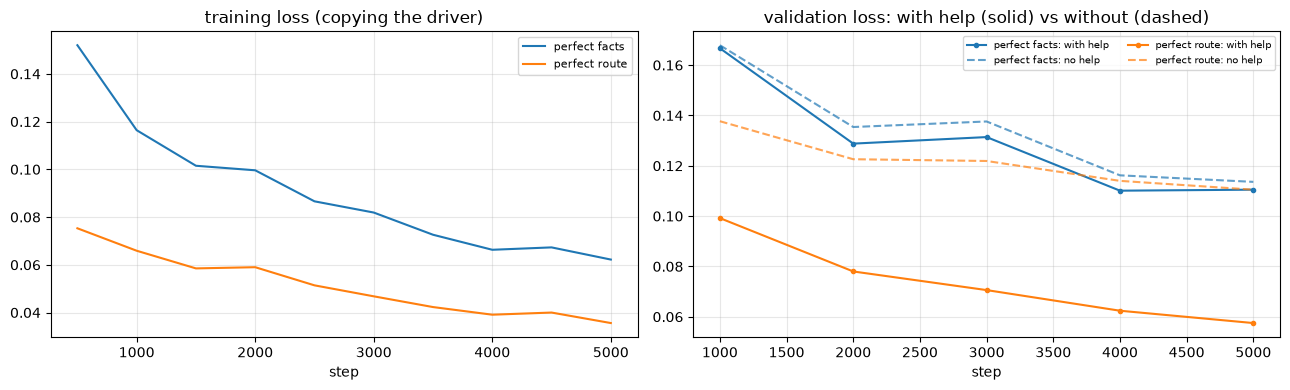

,success,goal hidden at start,box in the way,touched something,s per success,"s per success, hidden",failures,...stuck
car,,,,,,,,
front camera only,75%,69%,50%,52%,14.3,23.1,32,25
perfect facts,77%,63%,50%,46%,10.2,11.0,30,30
perfect route,99%,100%,95%,4%,6.8,8.8,1,1
perfect route: help OFF,58%,47%,35%,59%,11.7,16.6,54,44
perfect route: WRONG-room help,7%,2%,0%,98%,38.2,51.7,119,113


In [10]:
FORCE = False
nb06.run(["scripts/route_frames.py"], ["runs/overhead_frames/route_follow/route_true.npy"], force=FORCE)
nb06.run(["scripts/train_guided.py", "--model", "Rstar", "--init", CK / "car06_Cstar_s0.pt"], [CK / "car06_Rstar_s0.pt"],
         force=FORCE, log=RUNS / "car06_logs" / "Rstar_s0.log")
nb06.run(["scripts/car06_tests.py", "--car", CK / "car06_Rstar_s0.pt", "--out", "runs/car06_tests/car06_Rstar_s0.json"],
         ["runs/car06_tests/car06_Rstar_s0.json"], force=FORCE)
nb06.plot_car_training({"perfect facts": RUNS / "car06_logs/Cstar_s0.log", "perfect route": RUNS / "car06_logs/Rstar_s0.log"}); plt.show()
display(nb06.summary([("front camera only", "F_s0", "help"), ("perfect facts", "Cstar_s0", "help"),
                      ("perfect route", "car06_Rstar_s0", "help"), ("perfect route: help OFF", "car06_Rstar_s0", "no_help"),
                      ("perfect route: WRONG-room help", "car06_Rstar_s0", "other_room")]))

**A different picture altogether:**
* the training chart now shows a big gap: validation loss **0.058 with the route vs 0.111 without**;
* success **99%** (127 of 128), **95%** in the box-in-the-way rooms (every earlier car: 50%), 6.8 s per success;
* it touches something in only 4% of drives (front-camera car: 52%);
* wrong-room routes drop it to 7%: it follows the route faithfully.

One warning sign for later: with help **off** it manages only 58%, worse than the front-camera car (75%). It has
learned to depend on the route. That's fine while the server is always there, but it matters if help ever becomes
"ask only when needed".

## 8. Experiment 3: the real route, worked out by the server from the ceiling picture

The server now needs three things to plan a route: **where the obstacles are**, **where the car is (and which way it
faces)**, and **where the goal is**. Then a standard shortest-path planner does the rest (the same one the demo driver
uses: grow every obstacle by the car's radius, then find the shortest path).

For each of the three, we first tried the learned server, measured it, and kept it only where it was accurate
enough. Section 8.5 sums up the final division of work and why each choice was made.

### 8.1 Where the obstacles are: a learned map

Simple colour rules can't find the obstacles: they are greys, and so are three of the four floors. So the server
**learns** to draw an obstacle map (`carsim/server_map.py`): a small network (5.3 M parameters) reads the server's
cached picture tokens and marks each 10 cm floor cell of the room as blocked or free. Labels come free from the
simulator. The instruction isn't needed: the map is the same whatever the goal.

**A lesson from building it.** The first version learned to draw only the room's outer walls and nothing inside
them. The walls are always in the same place, so drawing them got a decent score while everything inside (only ~5%
of cells are blocked there) was ignored. Scoring **only the inside of the room** fixed it. Always check what your
loss rewards.

About 5 minutes of training on the 48,000 cached pictures.

already done: runs/checkpoints/server_map_s0.pt


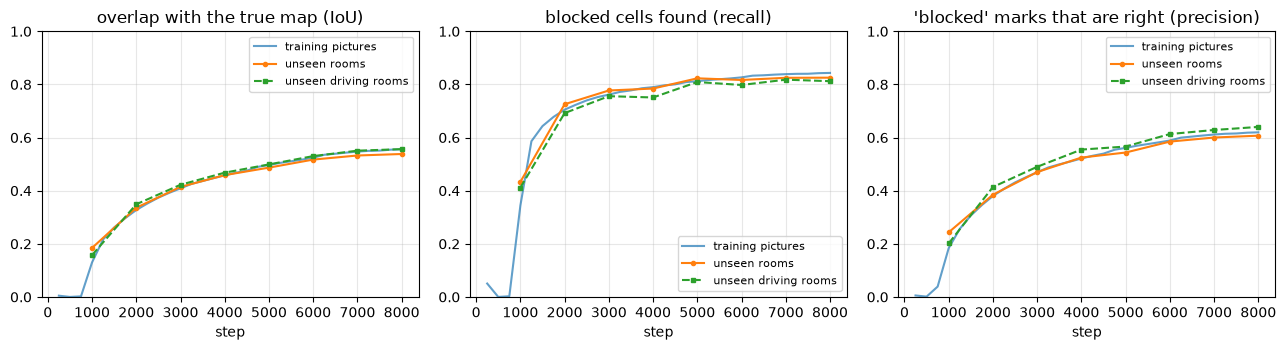

In [11]:
nb06.run(["scripts/train_server_map.py", "--steps", "8000"], [CK / "server_map_s0.pt"], force=False, log=RUNS / "server_logs" / "map_s0.log")
nb06.plot_map_training(torch.load(CK / "server_map_s0.pt", map_location="cpu")["log"]); plt.show()

**Reading the chart.** On rooms it never saw, the map finds about **82% of blocked cells**, and about **62% of the
cells it marks blocked really are** (it draws obstacles a little fat, which is the safer mistake). Training and
unseen-room scores are the same, so it isn't memorising. Both were still rising at the end, so longer training would
likely help.

### 8.2 Where the car is: why the learned server is not precise enough, and marker tracking

The server's facts put the car **0.45 m off** on average and read its heading **backwards ~4–7%** of the time. For a
route whose points are only 0.3–1 m ahead, that's fatal: a 0.5 m position error can make the next point appear in a
completely different direction.

**Why the learned model can't do better.** SmolVLM2 squeezes each 512 px tile into 8 × 8 tokens. On our camera, **one
token covers 0.55–1.06 m of floor**; the whole car (24–33 pixels) fits inside a quarter of one token. A 0.5 m error
is the model interpolating within one token. This is a known weakness: squeezing picture tokens keeps question
answering but destroys exact locations (e.g. 56% → 15% on an object-locating benchmark, arXiv 2506.21873), and VLMs
are generally poor at exact geometry (arXiv 2407.06581). After squeezing, the pink front and cyan back also blur
together, hence the backwards readings.

**Marker tracking** (`carsim/tracker.py`, no learning): find the pink and cyan pixels in the full-resolution picture,
take each blob's centre, and turn picture points into floor points using the camera's known position (a ray from the
camera through the pixel, cut at the marker's height). Heading = from the cyan centre to the pink centre, so it can't
come out backwards. This is how multi-robot labs track robots with a ceiling camera (e.g. the Robotarium, arXiv
1609.04730). We assume the camera is **calibrated** (it knows its own mounting, as a fixed real camera would after a
one-time calibration). Uncalibrated, the error grows to about 16 cm.

### 8.3 Where the goal is: the server picks *which*, colour finds *where*

The server's goal position is also ~0.46 m off, for the same reason. But the instruction names the goal's colour, and
the goal objects come in vivid colours (red, green, blue, yellow, purple, orange), unlike the grey floors and
obstacles. So: take the blob of the instruction's colour **closest to the server's rough position** (the server knows
the shape, which separates same-colour lookalikes), and place it on the floor with the same camera geometry.

The cell below tracks the car and refines the goal in all 15,494 driving frames (re-rendering each picture, about 15
minutes), then compares with the learned server.

In [12]:
nb06.run(["scripts/track_frames.py"], ["runs/overhead_frames/route_follow/tracker_pose.npy",
                                       "runs/overhead_frames/route_follow/goal_refined.npy"], force=False)
display(nb06.localisation_table())

already done: runs/overhead_frames/route_follow/tracker_pose.npy, runs/overhead_frames/route_follow/goal_refined.npy


,found,typical error,90% of frames within,note
what,,,,
car position: learned server,100.0%,0.47 m,0.88 m,
car position: marker tracking,99.9%,0.01 m,0.01 m,
car heading: learned server,100.0%,10.12 deg,70.37 deg,backwards (>90 deg): 7.4%
car heading: marker tracking,99.9%,0.85 deg,2.26 deg,backwards (>90 deg): 0.0%
goal position: learned server,100.0%,0.49 m,0.95 m,
goal position: server + colour,93.2%,0.02 m,0.04 m,> 0.6 m off: 7.3%


Marker tracking is about **60 times more precise** than the learned server for the car (about 1 cm and 1°, never
backwards), and colour refinement brings the goal from ~0.46 m to ~2 cm in 93% of frames.

### 8.4 How good are the real routes?

For every driving frame we plan a route on the server's own map and compare its next point with the perfect route's
(`scripts/server_route_frames.py`). Three versions show where the remaining errors come from.

In [13]:
nb06.run(["scripts/server_route_frames.py"], ["runs/overhead_frames/route_follow/route_pred.npy"], force=False)
nb06.run(["scripts/server_route_frames.py", "--tracker"], ["runs/overhead_frames/route_follow/route_tracked.npy"], force=False)
display(nb06.route_error_table())

already done: runs/overhead_frames/route_follow/route_pred.npy
already done: runs/overhead_frames/route_follow/route_tracked.npy


,typical error,off by > 45 deg,off by > 90 deg
route from,,,
learned server for everything,30 deg,34.0%,11.6%
tracker + learned map + colour-refined goal (used),3 deg,8.3%,2.8%
"learned map, but TRUE car + goal (map's own limit)",0 deg,4.5%,1.4%


With the learned server doing everything, a third of the route points point the wrong way (>45° off). With tracking
for the car and colour for the goal, that drops to **8%**, close to the map's own limit (4.5%). The map itself was
never the main problem: the positions were.

**One example** from a validation drive. The goal (red star) is behind a wall from where the car starts (blue arrow).
Left: the ceiling picture with what the tracker found. Middle: the true obstacles and the perfect route. Right: the
server's own learned map (true outlines in red) and the route it planned: around the wall, like the perfect one.

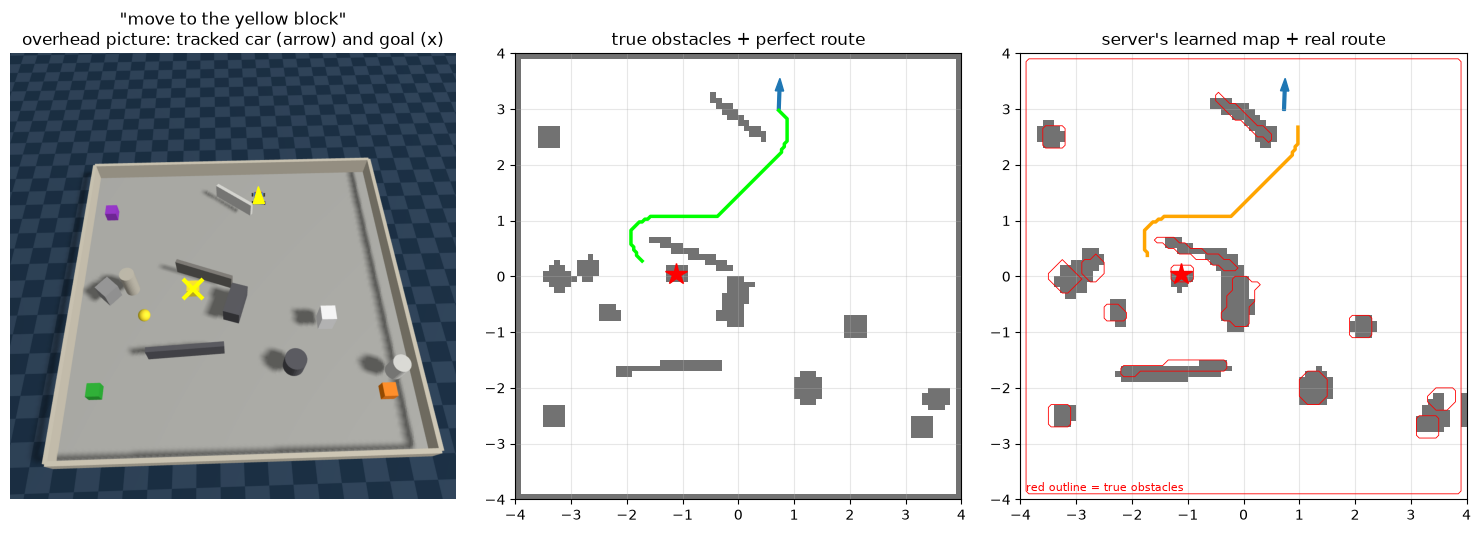

In [14]:
nb06.route_figure(2031); plt.show()

### 8.5 The final server: who does what, and why

The server is still the full **SmolVLM2-500M** (not smolVLA's reader). But in the final system it does only the
*understanding*; every exact number comes from a simple method that was measured to be far more precise.

| Job | Done by | Accuracy (driving frames, rooms never trained on) |
|---|---|---|
| Turn the ceiling picture into features | SmolVLM2's **vision part** (SigLIP encoder + connector): 4 tiles + whole view = 320 tokens | — |
| **Which object is the goal** (rough position) | SmolVLM2's **language part** (all 32 layers, last 4 fine-tuned) reading the picture **and the instruction**, + a small output head | ~0.46 m |
| **Where the obstacles are** | a small learned **map reader** (5.3 M parameters) on SmolVLM2's picture tokens | finds ~82% of blocked cells |
| Where the car is, which way it faces | **marker tracking**: pink + cyan blobs + camera geometry (no learning) | ~1 cm, ~1°, never backwards |
| Exactly where the goal is | **colour + geometry**: the instruction's colour blob nearest SmolVLM2's rough position | ~2 cm (found in 93% of frames) |
| The route | **shortest-path planner** on the map (no learning) | — |

What SmolVLM2's own outputs are still used for: its car position only as a fallback when the marker isn't found
(0.1% of frames), and its rough goal position directly when the colour isn't found (about 7%).

**The decisions, and the evidence behind each**

| Decision | Alternatives considered | Why this one |
|---|---|---|
| Server = full SmolVLM2, not smolVLA's 16-layer reader | the car's own reader; adding the ceiling picture to the car | the 16-layer, 64-token reader got the goal's rough direction right only 39–46% of the time; the full model with tiles reached ~75% (section 4); the car's reader couldn't use the ceiling picture at all (section 5) |
| Send a **route**, not facts or a message | facts (direction to the goal), an 8 × 128 message | even perfect directions didn't raise success; the perfect route did (75% → 99%) (sections 6–7) |
| Obstacles: **learned** map | colour rules; a depth camera / lidar | colour can't work (obstacles and three of the four floors are grey); a depth camera would add a sensor. The learned map keeps the camera RGB-only. Its output (a map) is the same as a depth camera's, so one can replace it later without changing the car. |
| Car position: **marker tracking** | the learned server's own estimate | the learned estimate is ~0.45 m off and backwards ~4–7% of the time, because one picture token covers 0.55–1.06 m of floor; for route points only 0.3–1 m ahead that is fatal. Tracking: ~1 cm. Standard practice for robots under a ceiling camera. |
| Goal: **SmolVLM2 picks which, colour finds where** | SmolVLM2's position alone | same token-size limit (~0.46 m); colour brings it to ~2 cm, and SmolVLM2's rough position tells same-colour lookalikes apart |
| Path: **geometric planner** | let the VLM plan | VLMs plan paths badly (Mobility VLA: 0% vs 90% with a planner; CoFL: 80–97% collisions) |

**The pattern: VLM for *what*, geometry for *where*.** The model is good at meaning (which object the words refer to,
what an obstacle looks like) and poor at exact positions. So each job goes to whichever does it best.

### 8.6 Train and test the real-route car

The car is trained exactly like the perfect-route car, but on the **real** routes of section 8.4 (so it learns the
server's real mistakes), with help removed 20% of the time. In the test, every half second the server reads the live
ceiling picture: tracker → car, learned map → obstacles, server + colour → goal, planner → 9 numbers to the car.

already done: runs/checkpoints/car06_R_s0.pt
already done: runs/car06_tests/car06_R_s0.json


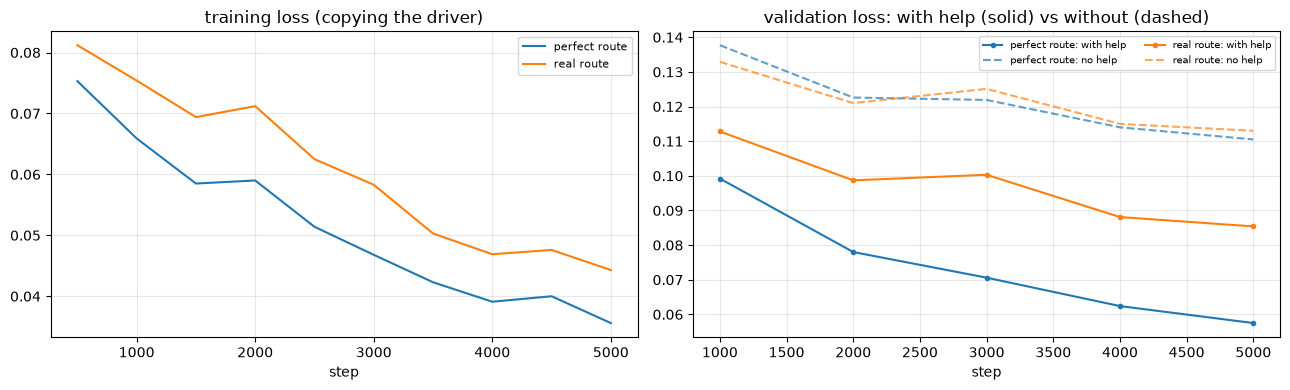

In [15]:
FORCE = False
nb06.run(["scripts/train_guided.py", "--model", "R", "--init", CK / "car06_Cstar_s0.pt"], [CK / "car06_R_s0.pt"],
         force=FORCE, log=RUNS / "car06_logs" / "R_s0.log")
nb06.run(["scripts/car06_tests.py", "--car", CK / "car06_R_s0.pt", "--server", SERVER, "--map", CK / "server_map_s0.pt",
          "--out", "runs/car06_tests/car06_R_s0.json"], ["runs/car06_tests/car06_R_s0.json"], force=FORCE)
nb06.plot_car_training({"perfect route": RUNS / "car06_logs/Rstar_s0.log", "real route": RUNS / "car06_logs/R_s0.log"}); plt.show()

### 8.7 Training the map longer

Most of the real-route car's failures were cars stuck on something, and the learned map missed about 18% of blocked
cells, so some routes clipped a box. The map had still been improving at the end of training, without overfitting, so
we trained it **five times longer** (40,000 steps, about 15 minutes), saved under a new name so the results above stay
as they were. Everything after it is rebuilt the same way: real routes, then car training, then live tests.

already done: runs/checkpoints/server_map_long_s0.pt


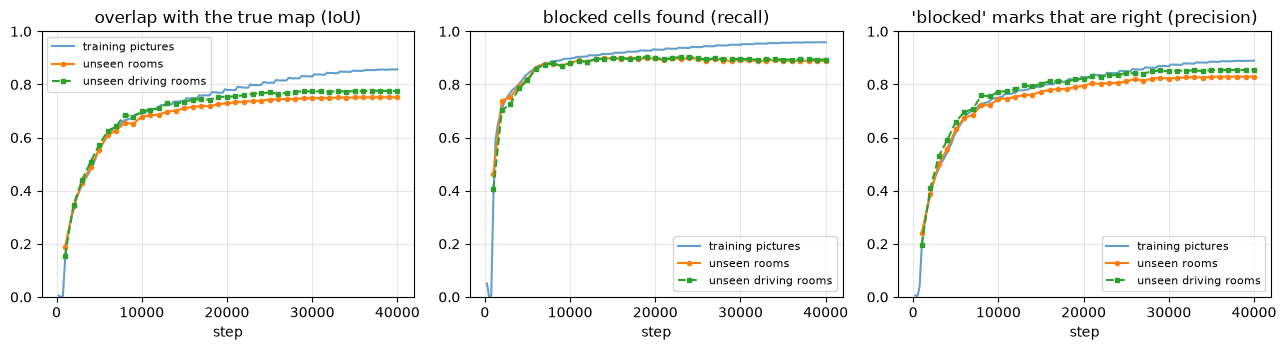

In [16]:
FORCE = False
MAP_LONG = CK / "server_map_long_s0.pt"
nb06.run(["scripts/train_server_map.py", "--steps", "40000", "--out", MAP_LONG], [MAP_LONG], force=FORCE, log=RUNS / "server_logs" / "map_long_s0.log")
nb06.plot_map_training(torch.load(MAP_LONG, map_location="cpu")["log"]); plt.show()

**Reading the chart: overfitting starts.** Up to about step 24,000, training pictures and unseen rooms improve
together. After that the training scores keep climbing (overlap 0.80 → 0.86) while unseen rooms level off (≈0.75), and
the share of blocked cells found on unseen rooms even dips slightly (0.90 → 0.89). The map is starting to learn its
training rooms by heart. A run of ~24,000 steps would have been just as good. The final map is still much better
than the 8,000-step one (unseen rooms: blocked cells found 82% → 89%; "blocked" marks that are right 62% → 83%).

What matters is the routes. We add one more measure, matching the failures: how often a route point lies where the
car would **touch a real obstacle**.

In [17]:
F = RUNS / "overhead_frames" / "route_follow"
nb06.run(["scripts/server_route_frames.py", "--tracker", "--tag", "_base"], [F / "route_tracked_base.npy"], force=False,
         log=RUNS / "server_logs" / "route_tracked_base.log")
nb06.run(["scripts/server_route_frames.py", "--tracker", "--tag", "_long", "--map", MAP_LONG], [F / "route_tracked_long.npy"],
         force=False, log=RUNS / "server_logs" / "route_tracked_long.log")
display(nb06.map_versions_table({"8,000-step map (sections 8.1-8.6)": RUNS / "server_logs" / "route_tracked_base.log",
                                 "40,000-step map": RUNS / "server_logs" / "route_tracked_long.log"}))

already done: runs/overhead_frames/route_follow/route_tracked_base.npy
already done: runs/overhead_frames/route_follow/route_tracked_long.npy


,blocked cells found (driving rooms),'blocked' marks right,route points touching an obstacle,route points off > 45 deg (real system),... with true car + goal (map's limit)
map,,,,,
"8,000-step map (sections 8.1-8.6)",82%,65%,1.76%,8.3%,4.5%
"40,000-step map",89%,86%,0.74%,6.0%,1.4%


Route points that would touch an obstacle drop from 1.8% to 0.7%, and the map's own limit (true car and goal) from
4.5% to 1.4% of points pointing the wrong way. Now the car, trained and tested exactly as in section 8.6 but on the new
routes and with the new map in the live server:

In [18]:
nb06.run(["scripts/train_guided.py", "--model", "R", "--init", CK / "car06_Cstar_s0.pt", "--route_file", "route_tracked_long.npy",
          "--out", CK / "car06_R_long_s0.pt"], [CK / "car06_R_long_s0.pt"], force=FORCE, log=RUNS / "car06_logs" / "R_long_s0.log")
nb06.run(["scripts/car06_tests.py", "--car", CK / "car06_R_long_s0.pt", "--server", SERVER, "--map", MAP_LONG,
          "--out", "runs/car06_tests/car06_R_long_s0.json"], ["runs/car06_tests/car06_R_long_s0.json"], force=FORCE)
display(nb06.summary([("front camera only", "F_s0", "help"), ("real route, 8,000-step map", "car06_R_s0", "help"),
                      ("real route, 40,000-step map", "car06_R_long_s0", "help"),
                      ("40,000-step map: help OFF", "car06_R_long_s0", "no_help"),
                      ("40,000-step map: WRONG-room help", "car06_R_long_s0", "other_room"),
                      ("perfect route", "car06_Rstar_s0", "help")]))
display(nb06.paired_table([
    ("40,000-step map vs 8,000-step map", ("car06_R_long_s0", "help"), ("car06_R_s0", "help")),
    ("40,000-step map vs front camera only", ("car06_R_long_s0", "help"), ("F_s0", "help")),
    ("40,000-step map vs perfect route", ("car06_R_long_s0", "help"), ("car06_Rstar_s0", "help"))]))

already done: runs/checkpoints/car06_R_long_s0.pt
already done: runs/car06_tests/car06_R_long_s0.json


,success,goal hidden at start,box in the way,touched something,s per success,"s per success, hidden",failures,...stuck
car,,,,,,,,
front camera only,75%,69%,50%,52%,14.3,23.1,32,25
"real route, 8,000-step map",91%,88%,80%,30%,9.3,12.0,12,11
"real route, 40,000-step map",94%,92%,90%,22%,8.0,11.0,8,7
"40,000-step map: help OFF",67%,53%,35%,55%,12.1,12.4,42,35
"40,000-step map: WRONG-room help",54%,55%,45%,81%,21.4,26.5,59,59
perfect route,99%,100%,95%,4%,6.8,8.8,1,1


,all rooms,goal hidden,box in the way
comparison,,,
"40,000-step map vs 8,000-step map",6:2 p = 0.289 (could be luck),3:1 p = 0.625 (could be luck),3:1 p = 0.625 (could be luck)
"40,000-step map vs front camera only",28:4 p = 0.000 (real),14:2 p = 0.004 (real),8:0 p = 0.008 (real)
"40,000-step map vs perfect route",0:7 p = 0.016 (real),0:4 p = 0.125 (could be luck),0:1 p = 1.000 (could be luck)


**What we found**
* Better on every measure: success **91% → 94%**, goal hidden at start 88% → 92%, box in the way 80% → 90%,
  drives touching something 30% → 22%, failures 12 → 8 (stuck 11 → 7), 9.3 → 8.0 s per success.
* **But the gain over the 8,000-step map is not proven**: only 8 rooms changed outcome (6 won, 2 lost, p = 0.29). A
  3-point difference needs more test rooms (512 instead of 128) or a second seed to confirm.
* Against the front-camera car it's now 28 rooms won, 4 lost. The perfect route is still measurably better (7 rooms
  won, 0 lost); the gap is cars stuck in the rooms needing the most detour.
* The car leans on the route even more: with help off, 67% (the 8,000-step-map car: 71%).

**The remaining failures are cars stuck on something.** The demonstrations never show how to back off an obstacle,
which is exactly what notebook 05's practice (PPO) taught. **Notebook 07 does that for this car.**

## 9. All results together

Same 128 test rooms for every car. "Box in the way" = the 20 rooms where the obstacle-free route is at least as long
as the straight line.

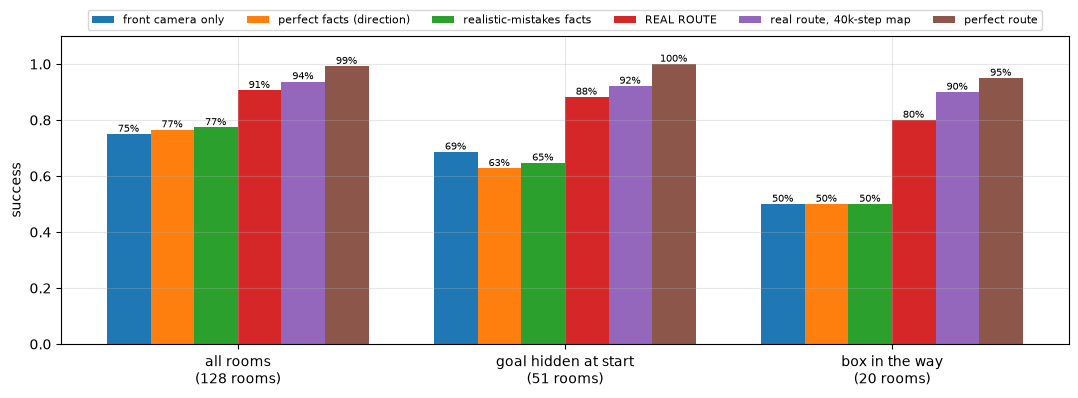

,success,goal hidden at start,box in the way,touched something,s per success,"s per success, hidden",failures,...stuck
car,,,,,,,,
front camera only,75%,69%,50%,52%,14.3,23.1,32,25
perfect facts (direction),77%,63%,50%,46%,10.2,11.0,30,30
realistic-mistakes facts,77%,65%,50%,55%,12.6,14.4,29,28
REAL ROUTE,91%,88%,80%,30%,9.3,12.0,12,11
"real route, 40k-step map",94%,92%,90%,22%,8.0,11.0,8,7
perfect route,99%,100%,95%,4%,6.8,8.8,1,1
real route: help OFF,71%,57%,35%,52%,13.4,18.7,37,27
real route: WRONG-room help,55%,55%,30%,88%,25.3,27.6,57,57


In [19]:
ALL = [("front camera only", "F_s0", "help"), ("perfect facts (direction)", "Cstar_s0", "help"),
       ("realistic-mistakes facts", "car06_Cn_s0", "help"), ("REAL ROUTE", "car06_R_s0", "help"),
       ("real route, 40k-step map", "car06_R_long_s0", "help"),
       ("perfect route", "car06_Rstar_s0", "help")]
nb06.results_chart(ALL); plt.show()
display(nb06.summary(ALL + [("real route: help OFF", "car06_R_s0", "no_help"), ("real route: WRONG-room help", "car06_R_s0", "other_room")]))

**Luck tests.** The fair way to compare two cars: same rooms, drive by drive. Count the rooms where only car A
succeeded (wins) and where only car B did (losses); rooms where both succeeded or both failed say nothing about the
difference. If the cars were equally good, wins and losses would be a coin toss; *p* is the chance of a split at
least this lopsided by luck alone (a sign test). Below 0.05 we call it real.

In [20]:
display(nb06.paired_table([
    ("perfect facts vs front camera only", ("Cstar_s0", "help"), ("F_s0", "help")),
    ("real route vs front camera only", ("car06_R_s0", "help"), ("F_s0", "help")),
    ("real route: help on vs off", ("car06_R_s0", "help"), ("car06_R_s0", "no_help")),
    ("real route: right vs wrong-room help", ("car06_R_s0", "help"), ("car06_R_s0", "other_room")),
    ("real route vs perfect route", ("car06_R_s0", "help"), ("car06_Rstar_s0", "help")),
]))
display(nb06.detour_thirds([("front camera only", "F_s0", "help"), ("real route", "car06_R_s0", "help"),
                            ("perfect route", "car06_Rstar_s0", "help")]))

,all rooms,goal hidden,box in the way
comparison,,,
perfect facts vs front camera only,20:18 p = 0.871 (could be luck),9:12 p = 0.664 (could be luck),4:4 p = 1.000 (could be luck)
real route vs front camera only,29:9 p = 0.002 (real),14:4 p = 0.031 (real),8:2 p = 0.109 (could be luck)
real route: help on vs off,27:2 p = 0.000 (real),17:1 p = 0.000 (real),9:0 p = 0.004 (real)
real route: right vs wrong-room help,48:3 p = 0.000 (real),18:1 p = 0.000 (real),10:0 p = 0.002 (real)
real route vs perfect route,0:11 p = 0.001 (real),0:6 p = 0.031 (real),0:3 p = 0.250 (could be luck)


,least detour,middle,most detour
car,,,
front camera only,84% (5 stuck),76% (8 stuck),65% (12 stuck)
real route,100% (0 stuck),88% (4 stuck),84% (7 stuck)
perfect route,100% (0 stuck),100% (0 stuck),98% (1 stuck)


### 9.1 What we found

The numbers are from the project's own run (seed 0); a rerun lands close to them but not exactly on them.

| | front camera only | perfect facts | **real route** | perfect route |
|---|---|---|---|---|
| success (128 rooms) | 75% | 77% | **91%** | 99% |
| ... goal hidden at start | 69% | 63% | **88%** | 100% |
| ... box in the way (20 rooms) | 50% | 50% | **80%** | 95% |
| drives that touched something | 52% | 46% | **30%** | 4% |
| seconds per success | 14.3 | 10.2 | **9.3** | 6.8 |

**1. The real route beats the front-camera car, and not by luck:** 29 rooms won and 9 lost (p = 0.002); with the goal
hidden at the start, 14 to 4 (p = 0.03).

**2. The car really reads the route:** with help switched off it drops to 71% (27 wins to 2 losses for help on), and
with the wrong room's route to 56% (48 to 3).

**3. What's left between real (91%) and perfect (99%):** 11 of its 12 failures are cars stuck on something. The
learned map misses about 18% of blocked cells, so some routes clip a box. The obvious next steps: train the map longer
(it was still improving), or replace it with a depth camera or lidar. The route message and the car don't change when
the map maker does; the car would only need retraining on the new map's (smaller) mistakes.

**3b. Training the map longer (section 8.7)** took the real-route car to **94%** (90% with a box in the way, 22% of
drives touching something). The gain over 91% is within luck on 128 rooms; the gain over the front camera is not (28
rooms won, 4 lost).

**4. Caveats.** One training seed per car. No network delay: the route is computed at the exact moment of each
decision, while on a real network it arrives late and the car may have moved ~0.4 m. The camera is assumed calibrated.
The box-in-the-way result (80% vs 50%) has only 20 rooms, so on its own it's suggestive (p = 0.11), not proven.

### 9.2 The lessons

* **Ask what kind of help the driver needs, not just how much information you can send.** The perfect *direction* was
  useless around obstacles; the same 9 numbers as a *route* took the car from 75% to 99%.
* **VLMs for *what*, geometry for *where*.** The VLM picks which object is the goal and learns what an obstacle looks
  like. Exact positions (marker tracking, colour + camera geometry) and paths (a planner) are done by simple, exact
  methods. Three times in this notebook the learned model was the bottleneck for an exact number, and three times
  the classical method fixed it.
* **Test whether a model uses its input:** switch it off, and swap in a wrong one. A car can look fine with help and
  turn out to ignore it.
* **Diagnose with data.** "Which rooms fail?" found the real problem (boxes in the way) that more training would
  never have fixed.

## 10. Summary and ideas to try next

**What we built:** a ceiling camera with a two-colour roof marker; route-following demonstrations; an off-car server
(SmolVLM2) that learned to read the room's facts and to draw an obstacle map; marker tracking and colour-based goal
finding; a route planner; and a car that takes 9 route numbers as 8 extra input tokens. With the real server it
succeeds in 91% of test rooms against 75% for the front camera alone, sending 36 bytes every half second.

**Ideas to try next**
* **Practice with route help (notebook 07):** the remaining failures are cars stuck on something, which is what
  notebook 05's practice fixed. Or swap in a depth camera / lidar for the map.
* **Lock in the result:** a second training seed for the real-route and front-camera cars, tested on more rooms (512
  instead of 128 halves the luck range).
* **Network delay:** send the route a little late and correct it with the car's own movement since the picture was
  taken, or train with delayed routes.
* **Ask only when needed:** today the car gets a route every half second. If one server guides many cars, a small
  "asker" could learn to request help only when needed, at a cost per request (Ask4Help, arXiv 2211.09960). The car
  currently depends on the route (58–71% without it), so an asker would have to ask *before* trouble, not after
  getting stuck.